In [1]:
library(ggplot2)
library(dplyr)

set.seed(123)

# Create a realistic in-memory dataset of 60 Congress members
n <- 60
congress <- data.frame(
  name = paste0("Member_", 1:n),
  type = sample(c("senator", "representative"), n, replace = TRUE, prob = c(0.25, 0.75)),
  gender = sample(c("M", "F"), n, replace = TRUE, prob = c(0.65, 0.35)),
  party = sample(c("Democrat", "Republican"), n, replace = TRUE),
  birthyear = round(rnorm(n, mean = 1964, sd = 10)),
  stringsAsFactors = FALSE
) %>%
  mutate(
    # Approximate age (using current year 2026)
    age = 2026 - birthyear,
    # Simulate social media accounts (e.g., Twitter, Facebook, YouTube, Instagram)
    # Younger members tend to have slightly more active accounts
    social_media_accounts = pmax(0, round(6 - 0.05 * age + ifelse(type == "senator", 0.5, 0) + rnorm(n, 0, 0.9)))
  )

head(congress)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




,name,type,gender,party,birthyear,age,social_media_accounts
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
1,Member_1,representative,F,Democrat,1974,52,4
2,Member_2,senator,M,Republican,1969,57,4
3,Member_3,representative,M,Democrat,1966,60,3
4,Member_4,senator,M,Democrat,1958,68,2
5,Member_5,senator,F,Democrat,1978,48,4
6,Member_6,representative,M,Republican,1958,68,2


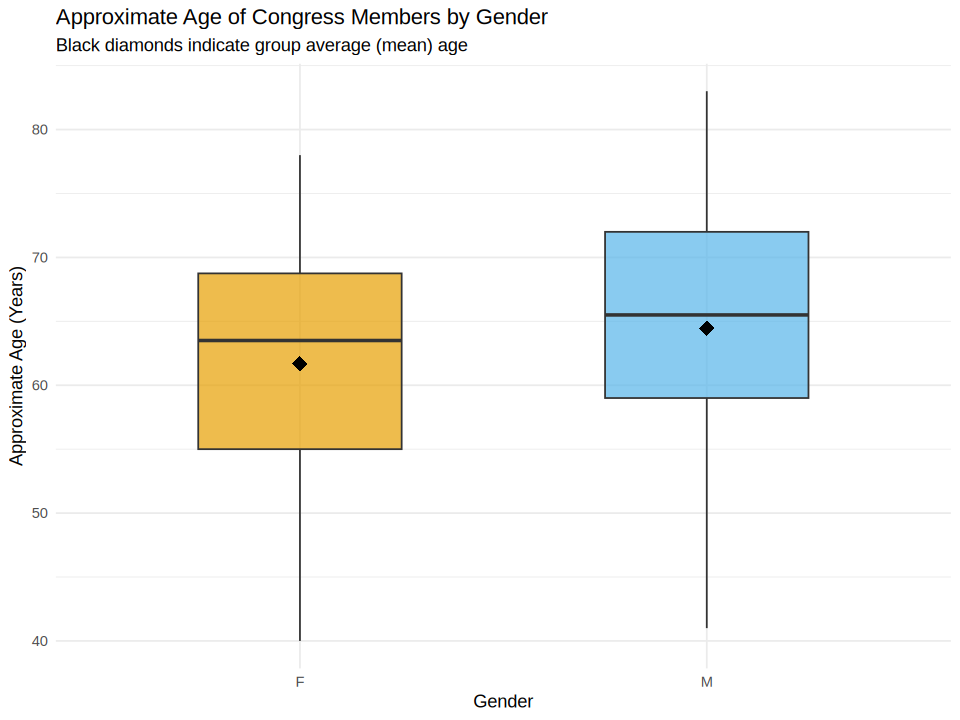

In [2]:
options(repr.plot.width = 8, repr.plot.height = 6)

ggplot(congress, aes(x = gender, y = age, fill = gender)) +
  geom_boxplot(alpha = 0.7, width = 0.5) +
  stat_summary(fun = mean, geom = "point", shape = 18, size = 4, color = "black") +
  scale_fill_manual(values = c("F" = "#E69F00", "M" = "#56B4E9")) +
  labs(
    title = "Approximate Age of Congress Members by Gender",
    subtitle = "Black diamonds indicate group average (mean) age",
    x = "Gender",
    y = "Approximate Age (Years)"
  ) +
  theme_minimal() +
  theme(legend.position = "none")

`geom_smooth()` using formula = 'y ~ x'


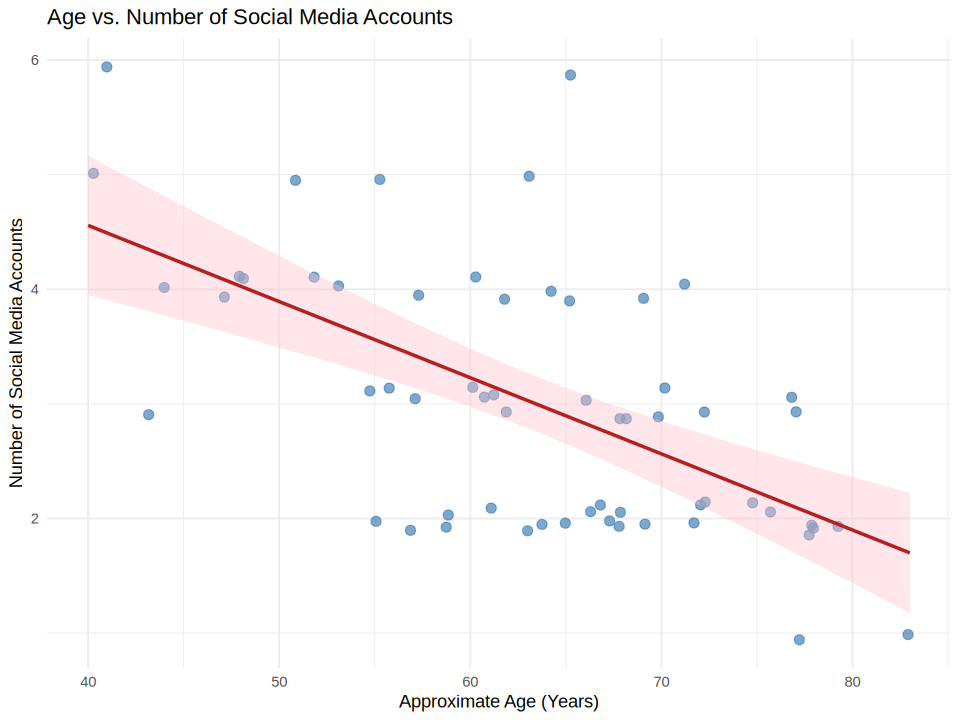

In [3]:
ggplot(congress, aes(x = age, y = social_media_accounts)) +
  geom_jitter(width = 0.3, height = 0.15, alpha = 0.7, color = "steelblue", size = 2.5) +
  geom_smooth(method = "lm", se = TRUE, color = "firebrick", fill = "pink") +
  labs(
    title = "Age vs. Number of Social Media Accounts",
    x = "Approximate Age (Years)",
    y = "Number of Social Media Accounts"
  ) +
  theme_minimal()

In [4]:
# Fit linear regression predicting social_media_accounts from type, age, party, and gender
model <- lm(social_media_accounts ~ type + age + party + gender, data = congress)

# Print detailed regression output
summary(model)


Call:
lm(formula = social_media_accounts ~ type + age + party + gender, 
    data = congress)

Residuals:
    Min      1Q  Median      3Q     Max 
-1.6854 -0.5266  0.0164  0.4487  3.2693 

Coefficients:
                Estimate Std. Error t value Pr(>|t|)    
(Intercept)      6.90954    0.74899   9.225 9.24e-13 ***
typesenator      0.40481    0.25497   1.588   0.1181    
age             -0.06069    0.01129  -5.376 1.60e-06 ***
partyRepublican  0.31577    0.22771   1.387   0.1711    
genderM         -0.54991    0.23878  -2.303   0.0251 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.8752 on 55 degrees of freedom
Multiple R-squared:  0.4599,	Adjusted R-squared:  0.4206 
F-statistic: 11.71 on 4 and 55 DF,  p-value: 6.008e-07
